# 4.7 자료 요약과 상관·산점도

기존 주택 자료 900행의 열 이름만 영어로 바꿉니다. 여러 수치 열의 상관과 개별 관측을 함께 보기에 적합합니다. 실측 여부와 가격 단위는 확인되지 않았습니다.

선정 이유: 기존 주택 자료 900행의 열 이름만 영어로 바꿉니다. 여러 수치 열의 상관과 개별 관측을 함께 보기에 적합합니다. 실측 여부와 가격 단위는 확인되지 않았습니다.

커널을 다시 시작한 뒤 각 셀을 위에서 아래로 실행합니다. 코드에는 가져오기와 함수 정의도 포함되어 있습니다.

## 셀 1 라이브러리 가져오기

가져오기(Import) 문장으로 경로 객체(Path)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 자바스크립트 객체 표기법(JavaScript Object Notation, JSON) 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 수치 배열 도구 넘파이(Numerical Python, NumPy)의 별칭 np를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 자료 표 도구 판다스(pandas)의 별칭 pd를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 맷플롯립 파이플롯(Matplotlib Pyplot)의 별칭 plt를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 셀 출력 표시 함수(display), 이미지 표시 객체(IPython Image)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

In [1]:
# 가져오기(Import) 문장으로 경로 객체(Path)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from pathlib import Path

# 가져오기(Import) 문장으로 자바스크립트 객체 표기법(JavaScript Object Notation, JSON) 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import json

# 가져오기(Import) 문장으로 수치 배열 도구 넘파이(Numerical Python, NumPy)의 별칭 np를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import numpy as np

# 가져오기(Import) 문장으로 자료 표 도구 판다스(pandas)의 별칭 pd를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import pandas as pd

# 가져오기(Import) 문장으로 맷플롯립 파이플롯(Matplotlib Pyplot)의 별칭 plt를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import matplotlib.pyplot as plt

# 가져오기(Import) 문장으로 셀 출력 표시 함수(display), 이미지 표시 객체(IPython Image)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from IPython.display import display, Image as NotebookImage

## 셀 2 입력·계산·출력 확인

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

변수 HERE를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 CHAPTER를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

입력 폴더(Data Directory, DATA)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

출력 폴더(Output Directory, OUT)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

앞 셀의 값을 사용해 OUT.mkdir(parents=True,exist_ok=True) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

검증 조건(Assertion)을 확인합니다. 거짓이면 셀을 중단하며 실패를 성공한 결과로 바꾸지 않습니다.

In [2]:
# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":11,"svg.fonttype":"none","axes.prop_cycle":plt.cycler(color=["black","0.45","0.7"]),"figure.figsize":(7,4.2)})

# 변수 HERE를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
HERE=Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()

# 변수 CHAPTER를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
CHAPTER=HERE if (HERE/"data").exists() else HERE.parent

# 입력 폴더(Data Directory, DATA)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
DATA=CHAPTER/"data"

# 출력 폴더(Output Directory, OUT)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
OUT=HERE/"results"/"sec_07_main"

# 앞 셀의 값을 사용해 OUT.mkdir(parents=True,exist_ok=True) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
OUT.mkdir(parents=True,exist_ok=True)

# 검증 조건(Assertion)을 확인합니다. 거짓이면 셀을 중단하며 실패를 성공한 결과로 바꾸지 않습니다.
assert DATA.exists(), f"장별 data 폴더를 함께 내려받으세요: {DATA}"

## 셀 3 함수와 모듈 정의

그림 저장 함수(figure)를 정의합니다. 실제 현재 그림을 벡터 형식과 300dpi 이미지로 저장하고 노트북에 표시합니다. 함수 정의와 뒤의 실제 호출을 구분합니다.

In [3]:
# 그림 저장 함수(figure)를 정의합니다. 실제 현재 그림을 벡터 형식과 300dpi 이미지로 저장하고 노트북에 표시합니다. 함수 정의와 뒤의 실제 호출을 구분합니다.
def figure(out,name):
    plt.tight_layout()
    plt.savefig(out/(name+".svg"),facecolor="white")
    plt.savefig(out/(name+".png"),dpi=300,facecolor="white")
    if "get_ipython" in globals():display(NotebookImage(filename=str(out/(name+".png"))))
    plt.close()

## 셀 4 함수와 모듈 정의

결과 기록 함수(report)를 정의합니다. 계산된 지표만 JSON과 문자 출력에 기록하며 비유한 수치를 성공값으로 바꾸지 않습니다.

In [4]:
# 결과 기록 함수(report)를 정의합니다. 계산된 지표만 JSON과 문자 출력에 기록하며 비유한 수치를 성공값으로 바꾸지 않습니다.
def report(out,name,metrics):
    text=json.dumps(metrics,ensure_ascii=False,indent=2,allow_nan=False)
    (out/(name+".json")).write_text(text,encoding="utf-8")
    print(text)

## 셀 5 입력·계산·출력 확인

쉼표 구분 자료(Comma Separated Values, CSV)를 읽습니다. 이 실습에서 선정한 입력 파일과 열 이름·목표 열을 확인합니다. 입력 자료의 선정 이유와 실제 행 수는 앞의 자료 설명을 따릅니다.

문자 출력(Print)으로 현재 결과를 확인합니다. 반올림된 표시값과 내부 배열의 정밀도는 다를 수 있습니다.

문자 출력(Print)으로 현재 결과를 확인합니다. 반올림된 표시값과 내부 배열의 정밀도는 다를 수 있습니다.

문자 출력(Print)으로 현재 결과를 확인합니다. 반올림된 표시값과 내부 배열의 정밀도는 다를 수 있습니다.

문자 출력(Print)으로 현재 결과를 확인합니다. 반올림된 표시값과 내부 배열의 정밀도는 다를 수 있습니다.

문자 출력(Print)으로 현재 결과를 확인합니다. 반올림된 표시값과 내부 배열의 정밀도는 다를 수 있습니다.

변수 corr를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 fig·변수 ax를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 im를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

반복문(Loop)의 조건에 따라 들여쓴 계산을 수행합니다. for i in range(len(corr)):에서 반복 대상과 횟수를 확인하고 종료 뒤에는 마지막 계산 상태가 남는다는 점에 주의합니다.

앞 셀의 값을 사용해 fig.colorbar(im, ax=ax, shrink=0.8) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

앞 셀의 값을 사용해 fig.tight_layout() 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

In [5]:
# 쉼표 구분 자료(Comma Separated Values, CSV)를 읽습니다. 이 실습에서 선정한 입력 파일과 열 이름·목표 열을 확인합니다. 입력 자료의 선정 이유와 실제 행 수는 앞의 자료 설명을 따릅니다.
df = pd.read_csv(DATA/"main_housing.csv")

# 문자 출력(Print)으로 현재 결과를 확인합니다. 반올림된 표시값과 내부 배열의 정밀도는 다를 수 있습니다.
print(f"Shape: {df.shape}")

# 문자 출력(Print)으로 현재 결과를 확인합니다. 반올림된 표시값과 내부 배열의 정밀도는 다를 수 있습니다.
print("상위 3개 행:")

# 문자 출력(Print)으로 현재 결과를 확인합니다. 반올림된 표시값과 내부 배열의 정밀도는 다를 수 있습니다.
print(df.head(3).to_string(index=False))

# 문자 출력(Print)으로 현재 결과를 확인합니다. 반올림된 표시값과 내부 배열의 정밀도는 다를 수 있습니다.
print("\n요약 통계량:")

# 문자 출력(Print)으로 현재 결과를 확인합니다. 반올림된 표시값과 내부 배열의 정밀도는 다를 수 있습니다.
print(df.describe().T[["mean", "std", "min", "max"]].round(2))

# 변수 corr를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
corr = df.corr(numeric_only=True)

# 변수 fig·변수 ax를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
fig, ax = plt.subplots(figsize=(6, 5))

# 변수 im를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
im = ax.imshow(corr, cmap="Greys", vmin=-1, vmax=1)

# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=35, ha="right")

# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
ax.set_yticks(range(len(corr.columns)), corr.columns)

# 반복문(Loop)의 조건에 따라 들여쓴 계산을 수행합니다. for i in range(len(corr)):에서 반복 대상과 횟수를 확인하고 종료 뒤에는 마지막 계산 상태가 남는다는 점에 주의합니다.
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9,
                color="white" if corr.iloc[i, j] > 0.0 else "black")

# 앞 셀의 값을 사용해 fig.colorbar(im, ax=ax, shrink=0.8) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
fig.colorbar(im, ax=ax, shrink=0.8)

# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
ax.set_title("Correlation Matrix")

# 앞 셀의 값을 사용해 fig.tight_layout() 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
fig.tight_layout()

Shape: (900, 6)
상위 3개 행:
  Area  Rooms  Age  Distance  School    Price
113.24      1   25     11.19   98.32 272368.0
153.84      1   35      2.25   48.75 326009.0
 91.21      3   25     24.81   54.77 251643.0

요약 통계량:
               mean       std       min        max
Area          94.72     29.50     25.00     188.79
Rooms          3.45      1.75      1.00       6.00
Age           25.39     14.32      0.00      49.00
Distance      12.33      7.02      0.20      25.00
School        69.12     17.31     40.01      99.98
Price     261573.07  81876.56  11576.00  485385.00


## 셀 6 입력·계산·출력 확인

실제 계산한 그림을 저장하고 표시합니다. 축·기호·범례의 의미는 이 실습의 결과 해설과 대조합니다.

실제 계산한 그림을 저장하고 표시합니다. 축·기호·범례의 의미는 이 실습의 결과 해설과 대조합니다.

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

변수 coef를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 xs를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

실제 계산한 그림을 저장하고 표시합니다. 축·기호·범례의 의미는 이 실습의 결과 해설과 대조합니다.

실제 계산한 수치를 결과 파일과 셀 출력에 기록합니다. 다른 데이터나 미실행 모델의 성능으로 해석하지 않습니다.

{
  "rows": 900,
  "area_price_correlation": 0.7651328794054775
}


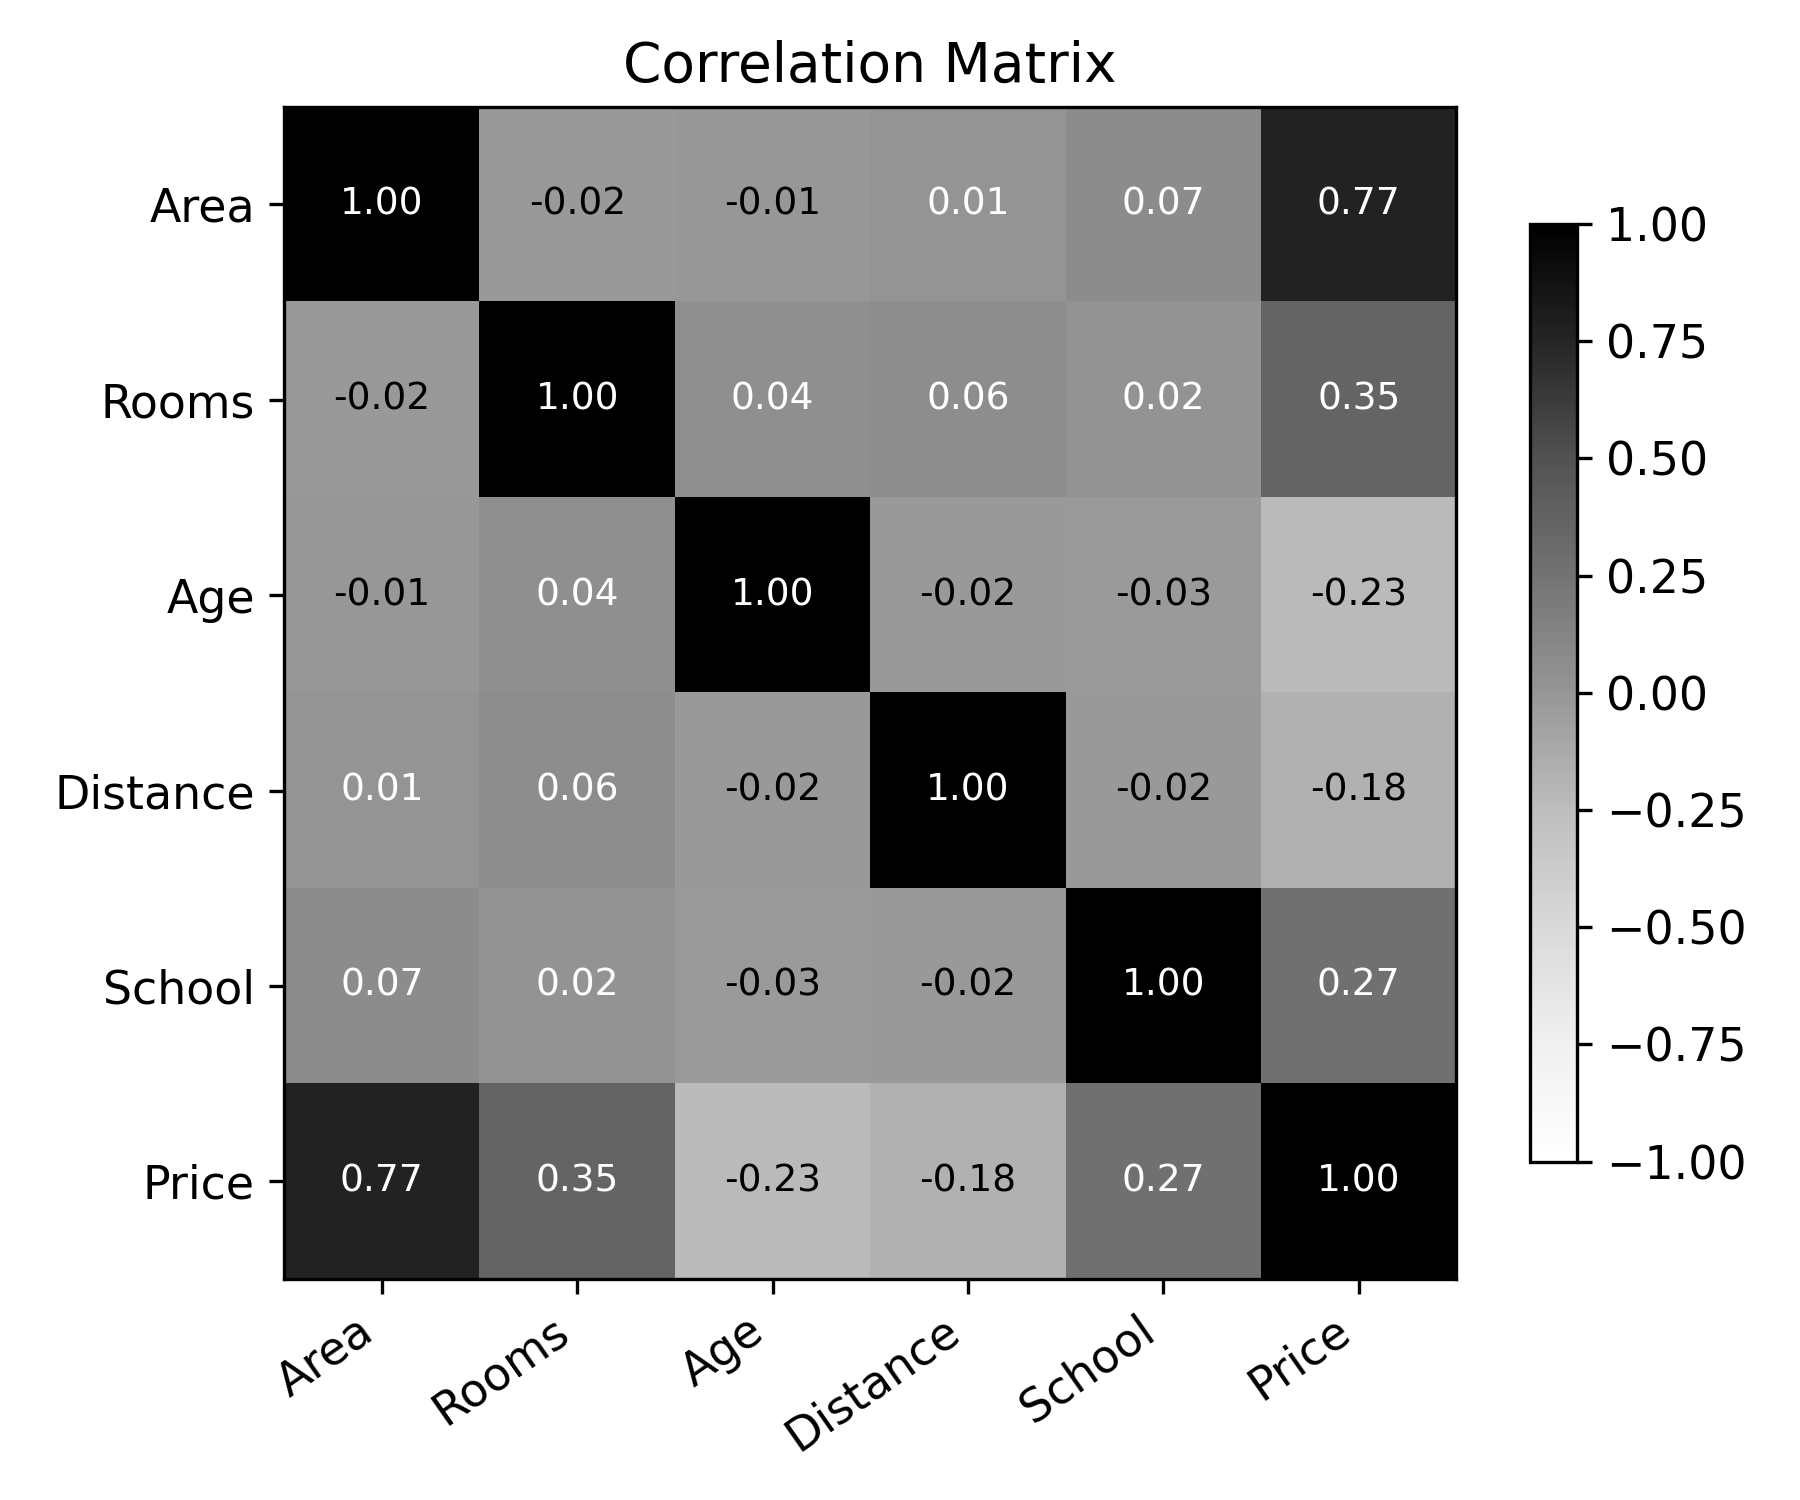

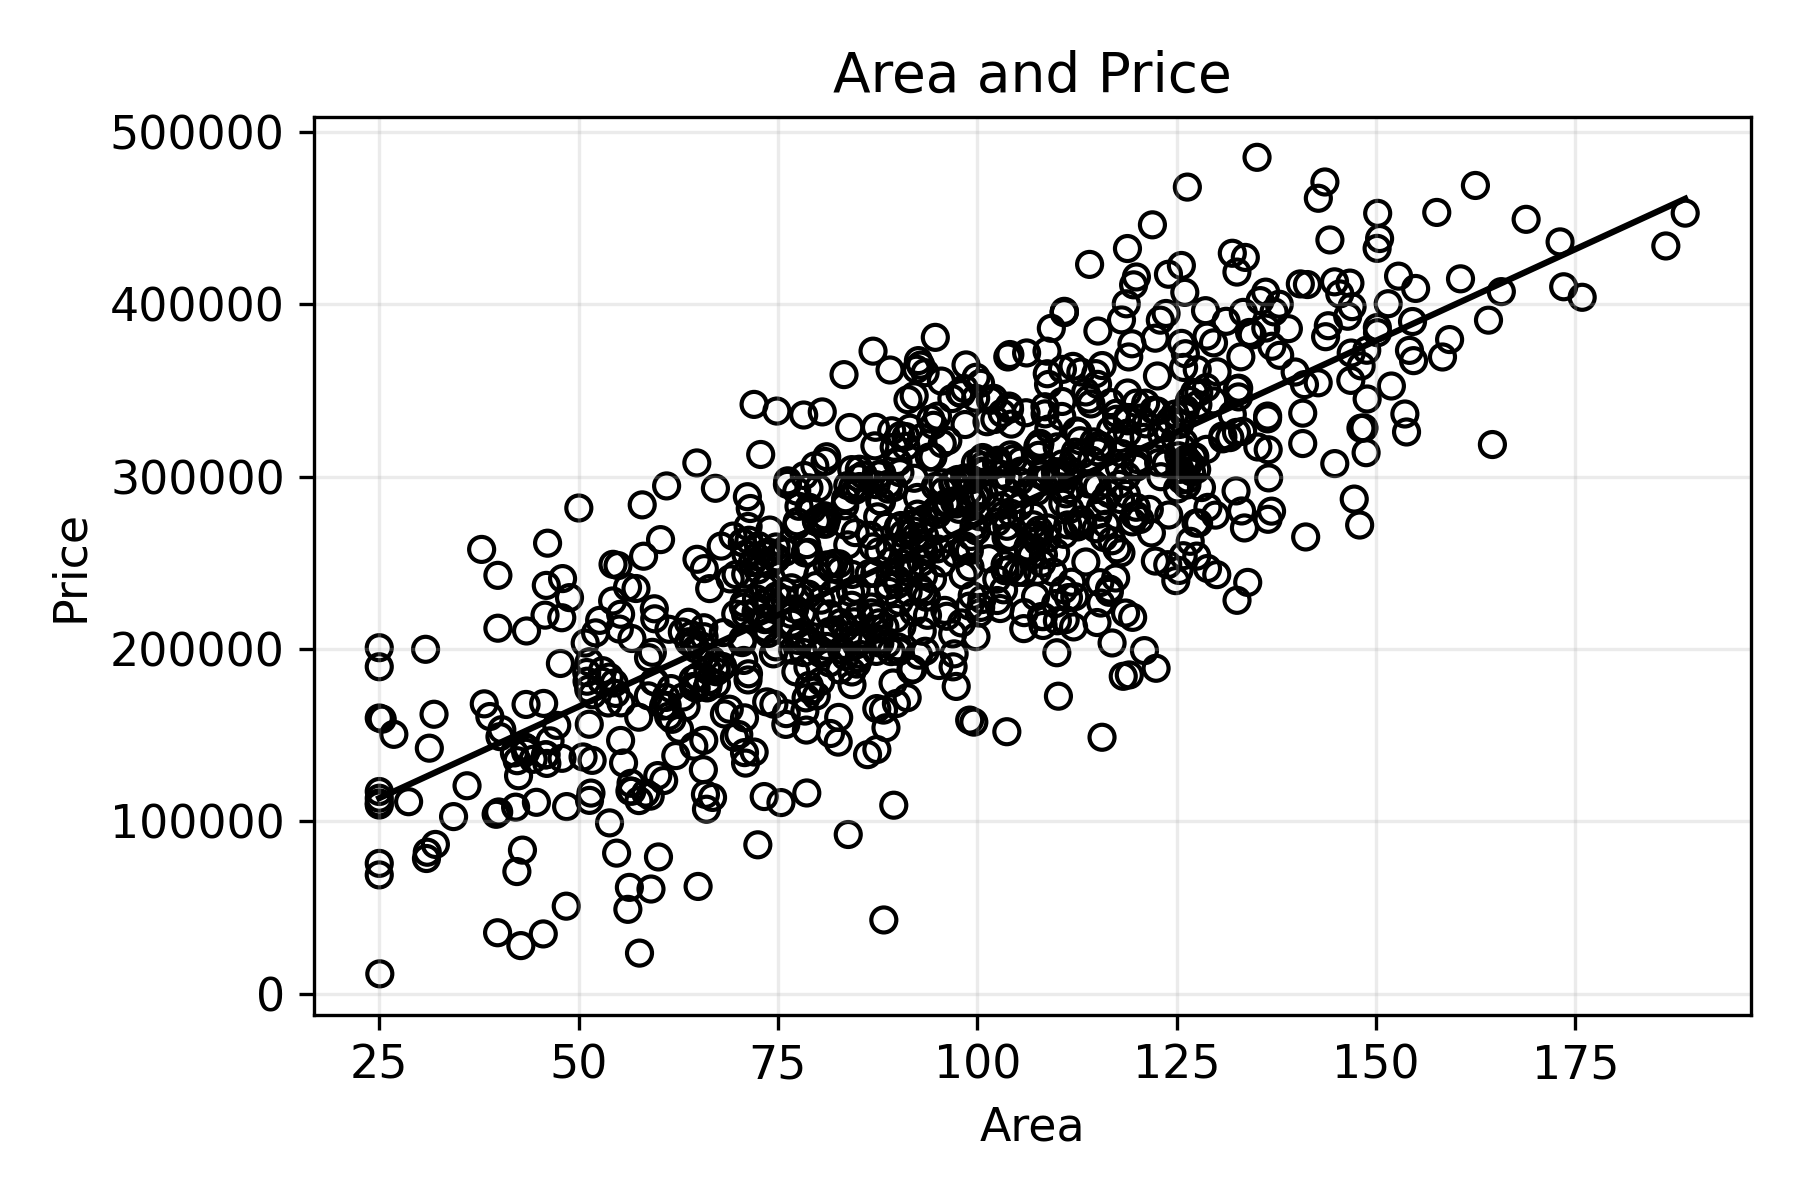

In [6]:
# 실제 계산한 그림을 저장하고 표시합니다. 축·기호·범례의 의미는 이 실습의 결과 해설과 대조합니다.
figure(OUT,"ch04_correlation_heatmap")

# 실제 계산한 그림을 저장하고 표시합니다. 축·기호·범례의 의미는 이 실습의 결과 해설과 대조합니다.
plt.figure(figsize=(6, 4))

# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
plt.scatter(df["Area"], df["Price"], facecolors="none", edgecolors="black")

# 변수 coef를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
coef = np.polyfit(df["Area"], df["Price"], 1)

# 변수 xs를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
xs = np.linspace(df["Area"].min(), df["Area"].max(), 100)

# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
plt.plot(xs, coef[0]*xs + coef[1], color="black")

# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
plt.xlabel("Area")

# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
plt.ylabel("Price")

# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
plt.title("Area and Price")

# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
plt.grid(alpha=0.25)

# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
plt.tight_layout()

# 실제 계산한 그림을 저장하고 표시합니다. 축·기호·범례의 의미는 이 실습의 결과 해설과 대조합니다.
figure(OUT,"ch04_area_price_scatter")

# 실제 계산한 수치를 결과 파일과 셀 출력에 기록합니다. 다른 데이터나 미실행 모델의 성능으로 해석하지 않습니다.
report(OUT,"summary",{"rows":len(df),"area_price_correlation":float(corr.loc["Area","Price"])})

## 그림과 결과 해석

상관행렬의 셀은 열 쌍이며 산점도의 점은 관측 한 행입니다. 상관이 인과관계임을 뜻하지 않습니다.